In [ ]:
import numpy as np

BOARD_ROWS = 6
BOARD_COLS = 6
WIN_STATE = (5, 5)
LOSE_STATE = (1, 4)
WALLS = [(2, 1), (2, 2),(3,1),(4,1)]  # Define walls as a list of tuples
START = (0, 0)
PENALTY = -0.7
#DETERMINISTIC = False
DETERMINISTIC = True


In [142]:
class State:

    def __init__(self, state=START, walls=[(1, 1)]):
        self.board = np.zeros([BOARD_ROWS, BOARD_COLS])
        self.state = state
        self.isEnd = False
        self.determine = DETERMINISTIC

        # Store walls as a set for fast lookup
        self.walls = set(walls)
        for r, c in self.walls:
            if 0 <= r < BOARD_ROWS and 0 <= c < BOARD_COLS:
                self.board[r, c] = -1  # Mark wall tiles on board array

    def giveReward(self):
        if self.state == WIN_STATE:
            return 1
        elif self.state == LOSE_STATE:
            return -1
        else:
            return 0

    def isEndFunc(self):
        if (self.state == WIN_STATE) or (self.state == LOSE_STATE):
            self.isEnd = True

    def _chooseActionProb(self, action):
        if action == "up":
            return np.random.choice(["up", "left", "right"], p=[0.8, 0.1, 0.1])
        if action == "down":
            return np.random.choice(["down", "left", "right"], p=[0.8, 0.1, 0.1])
        if action == "left":
            return np.random.choice(["left", "up", "down"], p=[0.8, 0.1, 0.1])
        if action == "right":
            return np.random.choice(["right", "up", "down"], p=[0.8, 0.1, 0.1])

    def nxtPosition(self, action):
        """Calculates next position without recursive traps."""
        if not self.determine:
            action = self._chooseActionProb(action)

        # Calculate intended target state
        if action == "up":
            nxtState = (self.state[0] - 1, self.state[1])
        elif action == "down":
            nxtState = (self.state[0] + 1, self.state[1])
        elif action == "left":
            nxtState = (self.state[0], self.state[1] - 1)
        else:
            nxtState = (self.state[0], self.state[1] + 1)

        # Check if next position is within board boundaries AND not in walls
        if (0 <= nxtState[0] < BOARD_ROWS) and (0 <= nxtState[1] < BOARD_COLS):
            if nxtState not in self.walls:
                return nxtState

        # Bounce back to current state if move is blocked by boundary or wall
        return self.state

    def showBoard(self):
        self.board[self.state] = 1
        for i in range(0, BOARD_ROWS):
            print("-----------------")
            out = "| "
            for j in range(0, BOARD_COLS):
                if self.board[i, j] == 1:
                    token = "*"
                elif self.board[i, j] == -1:
                    token = "z"
                else:
                    token = "0"
                out += token + " | "
            print(out)
        print("-----------------")

In [143]:
import numpy as np


class Agent:

    def __init__(self, walls=[(2, 1), (2, 2)]):
        self.states = []  # record all positions taken
        self.actions = ["up", "down", "left", "right"]
        self.walls = walls  # set custom walls passed as args
        self.State = State(walls=self.walls)
        self.isEnd = self.State.isEnd
        self.lr = 0.2
        self.exp_rate = 0.3
        self.decay_gamma = 0.9

        # initialise Q-values setup in blank board 
        self.Q_values = {}
        for i in range(BOARD_ROWS):
            for j in range(BOARD_COLS):
                self.Q_values[(i, j)] = {}
                for a in self.actions:
                    self.Q_values[(i, j)][a] = 0.0

    def chooseAction(self):
        # Epsilon-greedy action selection
        if np.random.uniform(0, 1) <= self.exp_rate:
            return np.random.choice(self.actions)
        else:
            mx_nxt_reward = -float("inf") 
            action = self.actions[0]
            current_position = self.State.state
            for a in self.actions:
                nxt_reward = self.Q_values[current_position][a]
                if nxt_reward > mx_nxt_reward:
                    action = a
                    mx_nxt_reward = nxt_reward
            return action

    def takeAction(self, action):
        position = self.State.nxtPosition(action)
        #preserves custom walls passed as args
        return State(state=position, walls=self.walls)

    def reset(self):
        self.states = []
        #preserves custom walls on episode reset
        self.State = State(walls=self.walls)
        self.isEnd = self.State.isEnd

    def play(self, rounds=10):
        i = 0
        while i < rounds:
            if self.State.isEnd:
                reward = self.State.giveReward()
                print("Game End Reward:", reward)

                # Backpropagate Monte Carlo return through trajectory
                for s in reversed(self.states):
                    state_pos, action_taken = s[0], s[1]
                    current_q = self.Q_values[state_pos][action_taken]
                    reward = current_q + self.lr * (
                        self.decay_gamma * reward - current_q
                    )
                    self.Q_values[state_pos][action_taken] = round(
                        float(reward), 3
                    )

                self.reset()
                i += 1
            else:
                action = self.chooseAction()

                # Record step trajectory
                self.states.append([self.State.state, action])

                # Execute transition
                self.State = self.takeAction(action)
                self.State.isEndFunc()
                self.isEnd = self.State.isEnd

    def showValues(self):
        for i in range(0, BOARD_ROWS):
            print("----------------------------------")
            out = "| "
            for j in range(0, BOARD_COLS):
                out += (
                    str("{:.2f}".format(self.Q_values[(i, j)].get("up")))
                    + ","
                    + str("{:.2f}".format(self.Q_values[(i, j)].get("down")))
                    + ","
                    + str("{:.2f}".format(self.Q_values[(i, j)].get("left")))
                    + ","
                    + str("{:.2f}".format(self.Q_values[(i, j)].get("right")))
                    + " | "
                )
            print(out)
        print("----------------------------------")

In [144]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


def plot_state_value_heatmap(
    q_values,
    grid_shape=(6, 6),
    start=(1, 0),
    walls=[],
    penalties={},
    goal=(5, 5),
    title="Q-Value Heatmap",
):
    height, width = grid_shape
    v_grid = np.zeros((height, width))

    # Convert walls to a set to avoid duplicate drawing calls
    wall_set = set(walls)

    #  extract Q-Values into 2D Grid
    if isinstance(q_values, dict):
        for state, actions in q_values.items():
            if isinstance(actions, dict):
                max_val = max(actions.values()) if actions else 0
            elif isinstance(actions, (list, np.ndarray)):
                max_val = np.max(actions) if len(actions) > 0 else 0
            else:
                max_val = float(actions) if actions is not None else 0

            if isinstance(state, tuple):
                r, c = state
                if r < height and c < width:
                    v_grid[r, c] = max_val
            elif isinstance(state, (int, np.integer)):
                r, c = divmod(int(state), width)
                if r < height and c < width:
                    v_grid[r, c] = max_val
    else:
        q_arr = np.array(q_values)
        if q_arr.ndim == 2:
            state_vals = np.max(q_arr, axis=1)
            v_grid = state_vals.reshape((height, width))
        elif q_arr.ndim == 1:
            v_grid = q_arr.reshape((height, width))

    # draw Heatmap 
    # annot=False so we can format cell annotations cleanly without text overlap
    plt.figure(figsize=(7, 5.5))
    ax = sns.heatmap(
        v_grid,
        annot=False,  # Turned off automatic numbers to prevent overlap
        cmap="viridis",
        cbar_kws={"label": "Expected Return V(s)"},
    )
    plt.title(title, fontsize=12, weight="bold")

    #Custom Text Overlay (Handles both numerical values and special labels
    for r in range(height):
        for c in range(width):
            pos = (r, c)
            val = v_grid[r, c]
            
            if pos == start:
                ax.text(
                    c + 0.5,
                    r + 0.5,
                    "START",
                    ha="center",
                    va="center",
                    color="white",
                    weight="bold",
                )

            if pos in wall_set:
                ax.text(
                    c + 0.5,
                    r + 0.5,
                    "WALL",
                    ha="center",
                    va="center",
                    color="white",
                    weight="bold",
                )
            elif pos in penalties:
                ax.text(
                    c + 0.5,
                    r + 0.4,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    color="white",
                )
                ax.text(
                    c + 0.5,
                    r + 0.75,
                    f"Cost {penalties[pos]}",
                    ha="center",
                    va="center",
                    color="red",
                    fontsize=8,
                    weight="bold",
                )
            elif pos == goal:
                ax.text(
                    c + 0.5,
                    r + 0.35,
                    "GOAL",
                    ha="center",
                    va="center",
                    color="yellow",
                    weight="bold",
                )
                ax.text(
                    c + 0.5,
                    r + 0.7,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    color="white",
                )
            else:
                ax.text(
                    c + 0.5,
                    r + 0.5,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    color="white" if val < 0.7 else "black",
                )

    plt.xlabel("Grid Column (X)")
    plt.ylabel("Grid Row (Y)")
    plt.tight_layout()
    plt.show()

initial Q-values ... 

{(0, 0): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (0, 1): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (0, 2): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (0, 3): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (0, 4): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (0, 5): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 0): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 1): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 2): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 3): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 4): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (1, 5): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (2, 0): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (2, 1): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (2, 2): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, (2, 3): {'up': 0.0, 'down': 0.0, 'left': 0.0, 'right': 0.0}, 

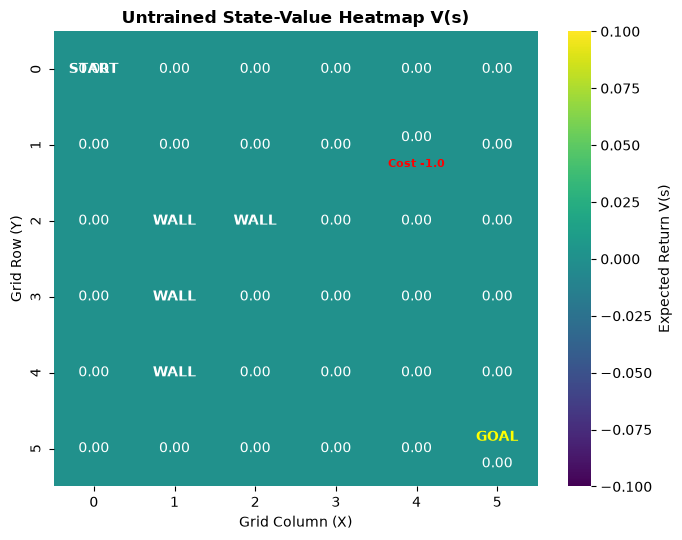

Game End Reward: -1
Game End Reward: -1
Game End Reward: -1
Game End Reward: -1
Game End Reward: -1
Game End Reward: -1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: -1
Game End Reward: -1
Game End Reward: -1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: -1
Game End Reward: -1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
Game End Reward: 1
G

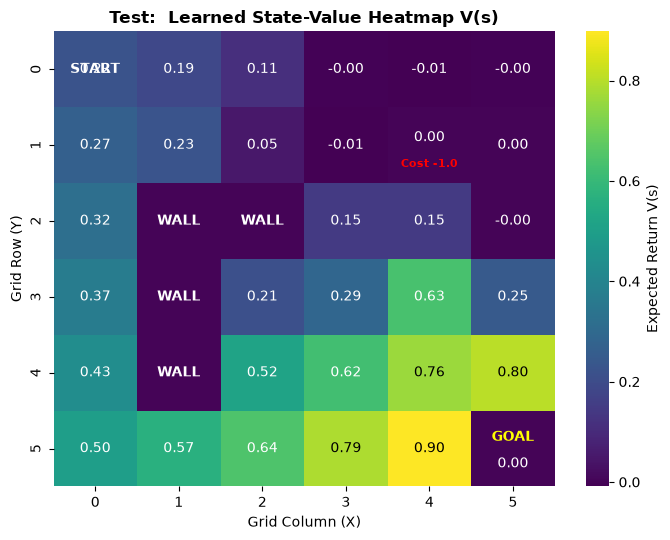

----------------------------------
| 0.14,0.22,0.17,0.13 | 0.09,0.09,0.19,0.06 | -0.00,-0.00,0.11,-0.01 | -0.01,-0.06,-0.00,-0.01 | -0.02,-0.32,-0.01,-0.01 | -0.01,-0.00,-0.02,-0.01 | 
----------------------------------
| 0.19,0.27,0.22,0.15 | 0.04,0.09,0.23,0.01 | -0.00,-0.01,0.05,-0.02 | -0.01,-0.02,-0.01,-0.66 | 0.00,0.00,0.00,0.00 | -0.01,0.00,0.00,0.00 | 
----------------------------------
| 0.22,0.32,0.26,0.24 | 0.00,0.00,0.00,0.00 | 0.00,0.00,0.00,0.00 | -0.12,0.15,0.03,-0.01 | -0.44,0.15,0.00,0.00 | -0.00,-0.00,0.00,0.00 | 
----------------------------------
| 0.28,0.37,0.29,0.30 | 0.00,0.00,0.00,0.00 | 0.12,0.13,0.02,0.21 | 0.03,0.20,0.12,0.29 | -0.04,0.63,0.10,0.11 | -0.00,0.25,-0.01,0.04 | 
----------------------------------
| 0.31,0.43,0.35,0.36 | 0.00,0.00,0.00,0.00 | 0.17,0.18,0.06,0.52 | 0.14,0.62,0.28,0.35 | 0.21,0.76,0.41,0.46 | -0.00,0.80,0.07,0.00 | 
----------------------------------
| 0.33,0.41,0.43,0.50 | 0.47,0.48,0.37,0.57 | 0.47,0.52,0.48,0.64 | 0.50,0.69,0.58,

In [ ]:
if __name__ == "__main__":
    """
    run the training with configured constants 
    """
    
    ag = Agent(walls=WALLS)  # Pass the walls to the Agent
    print("initial Q-values ... \n")
    print(ag.Q_values)

    # Plot initial untrained state values
    plot_state_value_heatmap(
        ag.Q_values,
        grid_shape=(BOARD_ROWS, BOARD_COLS),
        start=START,
        walls=WALLS,  # Add your environment's wall coordinates
        penalties={LOSE_STATE: PENALTY},   # Add your environment's energy penalty tiles
        goal=WIN_STATE, 
        title="Untrained State-Value Heatmap V(s)",
    )

    ag.play(500)
    print("latest Q-values ... \n")
    print(ag.Q_values)

    # Plot learned state values
    plot_state_value_heatmap(
        ag.Q_values,
        grid_shape=(BOARD_ROWS, BOARD_COLS),
        start=START,
        walls=WALLS,  # Add your environment's wall coordinates
        penalties={LOSE_STATE: PENALTY},   # Add your environment's energy penalty tiles
        goal=WIN_STATE,  # Your goal tile coordinates
        title="Test:  Learned State-Value Heatmap V(s)",
    )

    ag.showValues()